# 07 — Klasifikasi SVM Enam Kelas: Perbandingan Faktorial 2×3 dengan Seleksi Murni *Train CV*

## Ringkasan utama

Notebook ini mendokumentasikan **klasifikasi tingkat citra (*image-level*) enam kelas** pada dataset EBHI-SEG menggunakan *Support Vector Machine* (SVM) untuk membandingkan seluruh desain **2×3** (`otsu_M0`, `otsu_M1`, `otsu_M2`, `k4_M0`, `k4_M1`, `k4_M2`) bersama **Set A bersama** (fitur *appearance* 10 dimensi yang independen terhadap segmentasi) dan analisis sensitivitas sekunder `A_seg`/`C_seg` pada `k4_M0`.

### Pembaruan protokol eksperimen (`v1` $\rightarrow$ `v2`)
1. **Perluasan cakupan 2×3 penuh:** tahap 07 versi awal (`v1`, tersimpan utuh di `results/classification/` dan `models/svm_*.json`) hanya menguji 4 komparator (`otsu_M0`, `otsu_M2`, `k4_M0`, `k4_M1`) dan menggunakan hiperparameter Set C `k4_M0` untuk komparator lain serta skor `val` pada seleksi `k4_M0`.
2. **Pencarian hiperparameter identik & bebas kebocoran (*leak-free*) pada `v2` (`results/classification_2x3/` & `models/cv_2x3/`):**
   - Setiap dari **15 kombinasi `(konfigurasi, set_fitur)`** (`shared_appearance A`, 6 konfigurasi $\times$ `{Set B, Set C}`, serta `k4_M0` $\times$ `{A_seg, C_seg}`) menjalani **pencarian grid 32 spesifikasi yang identik** (`linear`/`rbf` $\times$ `C ∈ {0.1, 1, 3, 10}` $\times$ `gamma ∈ {scale, 0.01, 0.1}` $\times$ `class_weight ∈ {none, balanced}`).
   - Hiperparameter dipilih **strictly hanya menggunakan *5-fold StratifiedGroupKFold Macro-F1* pada data latih (`train`, 1.535 citra, 247 grup)**, dengan `StandardScaler` dipasang **di dalam tiap fold CV** untuk mencegah kebocoran informasi antar-fold.
   - Model terpilih kemudian dilatih ulang pada seluruh `train` dan dievaluasi **hanya sebagai evaluasi akhir validasi** pada `val` (`372` citra, `53` grup). Skor `val` **tidak pernah digunakan** untuk memilih hiperparameter, dan subset **`test` (`319` citra) sama sekali tidak diakses**.
3. **Konservasi artefak terdahulu:** seluruh hasil `v1` (`results/classification/*`, `models/svm_*.json`) dipertahankan tanpa penimpaan agar rekam historis Tahap 08 dan kontras protokol tetap transparan.


## Konteks, kontrak ilmiah, dan integritas kohort

- **Otoritas kohort:** `split_manifest.csv` diverifikasi secara *raw-byte* (`ceeba8e2...`). Karena terdapat `74` `group_id` multi-kategori, pemodelan dilakukan *image-level* namun pembagian CV maupun `train`/`val` tetap *group-disjoint*.
- **Independensi Set A:** Set A (10 fitur warna CIE Lab + GLCM seluruh piksel) diverifikasi identik di keenam tabel fitur sehingga dievaluasi satu kali sebagai **`shared_appearance A`**.
- **Aturan seleksi (`cv_selection_key_for_svm`):** berurutan memakai `cv_macro_f1` OOF (4 desimal) $\rightarrow$ `cv_balanced_accuracy` (4 desimal) $\rightarrow$ `cv_accuracy` (4 desimal) $\rightarrow$ `cv_fold_macro_f1_mean` (4 desimal) $\rightarrow$ kernel lebih sederhana (`linear > rbf`) $\rightarrow$ regularisasi lebih kuat (`-C`) $\rightarrow$ `gamma` lebih lebar $\rightarrow$ `class_weight='none' > 'balanced'`.


In [1]:
%matplotlib inline

import json
from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

from ebhi_dip import (
    CLASSIFICATION_2X3_DIR_REL,
    COMPARISON_2X3_METHODS,
    DECISION_PARITY_ATOL,
    EXPECTED_CATEGORIES,
    MODELS_CV_2X3_DIR_REL,
    PRIMARY_FEATURE_METHOD,
    SHARED_APPEARANCE_METHOD,
    apply_standard_scaler,
    classification_metrics,
    configure_notebook_style,
    confusion_matrix_table,
    cv_selection_key_for_svm,
    feature_columns_for_set,
    find_project_root,
    finish_figure,
    fit_standard_scaler,
    fit_svm_model,
    load_classification_feature_frame,
    load_shared_appearance_frame,
    load_svm_artifact,
    load_validation_results,
    method_label,
    predict_from_svm_artifact,
    sha256_bytes,
    summarize_validation_methods,
    verify_frozen_split,
    verify_svm_artifact_parity,
)

PROJECT_ROOT_OVERRIDE = None
EXPORT_FIGURES = False
PRIMARY_METHOD = PRIMARY_FEATURE_METHOD
FEATURE_METHODS = COMPARISON_2X3_METHODS

ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
SPLIT_SHA = verify_frozen_split(ROOT)
CLS_2X3_DIR = ROOT / CLASSIFICATION_2X3_DIR_REL
CLS_LEGACY_DIR = ROOT / "results/classification"
FEATURE_DIR = ROOT / "results/features"
MODELS_2X3_DIR = ROOT / MODELS_CV_2X3_DIR_REL
configure_notebook_style()

protected_files = {
    "split_manifest": ROOT / "data/metadata/split_manifest.csv",
    "feature_manifest_2x3": FEATURE_DIR / "feature_manifest_2x3.json",
    "diagnostics_2x3": FEATURE_DIR / "morphology_diagnostics_2x3.csv",
    "appearance": FEATURE_DIR / "appearance.csv",
    "segmented_manifest": FEATURE_DIR / f"feature_manifest_segmented_{PRIMARY_METHOD}.json",
    "segmented_features": FEATURE_DIR / f"features_{PRIMARY_METHOD}_segmented.csv",
    "legacy_cls_manifest": CLS_LEGACY_DIR / "classification_manifest.json",
    "legacy_cls_summary": CLS_LEGACY_DIR / "svm_selected_summary.csv",
    "legacy_cls_comp": CLS_LEGACY_DIR / "svm_comparator_sensitivity.csv",
    "cls_2x3_manifest": CLS_2X3_DIR / "classification_2x3_manifest.json",
    "svm_2x3_grid": CLS_2X3_DIR / "svm_2x3_grid_results.csv",
    "svm_2x3_summary": CLS_2X3_DIR / "svm_2x3_selected_summary.csv",
    "svm_2x3_per_cat": CLS_2X3_DIR / "svm_2x3_per_category_val.csv",
    "svm_2x3_seg_cls": CLS_2X3_DIR / "svm_2x3_segmentation_vs_classification.csv",
    "svm_2x3_val_pred": CLS_2X3_DIR / "svm_2x3_val_predictions.csv",
}
protected_files.update({f"features_{m}": FEATURE_DIR / f"features_{m}.csv" for m in FEATURE_METHODS})
input_hashes_before = {name: sha256_bytes(path) for name, path in protected_files.items()}

display(
    pd.DataFrame(
        {
            "komponen": [
                "Python",
                "NumPy",
                "pandas",
                "scikit-learn",
                "Matplotlib",
                "Konfigurasi 2x3",
                "Seleksi hiperparameter",
                "Akses held-out test",
            ],
            "nilai": [
                platform.python_version(),
                np.__version__,
                pd.__version__,
                sklearn.__version__,
                matplotlib.__version__,
                ", ".join(FEATURE_METHODS),
                "5-fold StratifiedGroupKFold Macro-F1 pada train saja",
                "DILARANG (test_images_touched == 0)",
            ],
        }
    )
)


,komponen,nilai
0,Python,3.14.0
1,NumPy,2.5.4
2,pandas,3.1.1
3,scikit-learn,1.9.1
4,Matplotlib,3.11.2
5,Konfigurasi 2x3,"otsu_M0, otsu_M1, otsu_M2, k4_M0, k4_M1, k4_M2"
6,Seleksi hiperparameter,5-fold StratifiedGroupKFold Macro-F1 pada trai...
7,Akses held-out test,DILARANG (test_images_touched == 0)


## 1. Verifikasi isolasi *split* (`train` / `val`), keseimbangan kelas, dan kontrak seleksi CV

Sel ini memuat seluruh tabel 2×3 dari `results/classification_2x3/`, membuktikan tidak ada baris atau label `test` yang disentuh, serta memverifikasi bahwa aturan `cv_selection_key_for_svm` menghasilkan pemilihan hiperparameter yang sama persis sekalipun skor `val` disamarkan.


In [2]:
cls_manifest = json.loads(protected_files["cls_2x3_manifest"].read_text(encoding="utf-8"))
grid_df = pd.read_csv(protected_files["svm_2x3_grid"])
summary_df = pd.read_csv(protected_files["svm_2x3_summary"])
per_cat_df = pd.read_csv(protected_files["svm_2x3_per_cat"])
seg_cls_df = pd.read_csv(protected_files["svm_2x3_seg_cls"])
val_pred_df = pd.read_csv(protected_files["svm_2x3_val_pred"])

train_app, val_app, loaded_sha = load_shared_appearance_frame(ROOT)
assert loaded_sha == SPLIT_SHA == cls_manifest["split_sha256"]
assert cls_manifest["cohort_counts"]["test_images_touched"] == 0
assert cls_manifest["cohort_counts"]["test_labels_accessed"] is False
assert set(val_pred_df["split"]) == {"val"}
assert len(train_app) == 1535 and len(val_app) == 372

# Confirm hyperparameter selection on all 15 combinations never depends on val_* columns
for (method, fset), grp in grid_df.groupby(["method", "feature_set"], sort=False):
    sel_row = grp.loc[grp["is_selected_best"]].iloc[0]
    masked_records = [
        {k: (-999.0 if str(k).startswith("val_") else v) for k, v in rec.items()}
        for rec in grp.to_dict("records")
    ]
    re_selected = max(masked_records, key=cv_selection_key_for_svm)
    assert (
        str(sel_row["kernel"]),
        str(sel_row["class_weight"]),
        float(sel_row["C"]),
        str(sel_row["gamma"]),
    ) == (
        str(re_selected["kernel"]),
        str(re_selected["class_weight"]),
        float(re_selected["C"]),
        str(re_selected["gamma"]),
    )

class_balance = pd.DataFrame(
    {
        "train_images": train_app["category"].value_counts().reindex(EXPECTED_CATEGORIES),
        "train_groups": train_app.groupby("category", observed=True)["group_id"].nunique().reindex(EXPECTED_CATEGORIES),
        "val_images": val_app["category"].value_counts().reindex(EXPECTED_CATEGORIES),
        "val_groups": val_app.groupby("category", observed=True)["group_id"].nunique().reindex(EXPECTED_CATEGORIES),
    }
)
class_balance["train_share_pct"] = 100.0 * class_balance["train_images"] / len(train_app)
class_balance["val_share_pct"] = 100.0 * class_balance["val_images"] / len(val_app)
class_balance.loc["TOTAL"] = [
    int(class_balance["train_images"].sum()),
    int(train_app["group_id"].nunique()),
    int(class_balance["val_images"].sum()),
    int(val_app["group_id"].nunique()),
    100.0,
    100.0,
]

display(
    class_balance.style.format(
        {
            "train_images": "{:.0f}",
            "train_groups": "{:.0f}",
            "val_images": "{:.0f}",
            "val_groups": "{:.0f}",
            "train_share_pct": "{:.2f}%",
            "val_share_pct": "{:.2f}%",
        }
    )
)
print(
    f"Verifikasi CV-selection lulus untuk semua {grid_df.groupby(['method', 'feature_set']).ngroups} kombinasi "
    f"({len(grid_df)} titik evaluasi grid; 0 citra test disentuh)."
)


,train_images,train_groups,val_images,val_groups,train_share_pct,val_share_pct
category,,,,,,
Adenocarcinoma,540,75,131,15,35.18%,35.22%
High-grade IN,131,28,20,5,8.53%,5.38%
Low-grade IN,444,101,107,21,28.93%,28.76%
Normal,54,11,10,3,3.52%,2.69%
Polyp,324,81,96,21,21.11%,25.81%
Serrated adenoma,42,10,8,2,2.74%,2.15%
TOTAL,1535,247,372,53,100.00%,100.00%


Verifikasi CV-selection lulus untuk semua 15 kombinasi (480 titik evaluasi grid; 0 citra test disentuh).


### Temuan 1 — isolasi `train`/`val` dan ketimpangan antar-kategori

- Tiga kategori mayoritas (`Adenocarcinoma`, `Low-grade IN`, `Polyp`) menguasai **85,21% data `train`** dan **89,78% data `val`**, sementara tiga kategori minoritas (`High-grade IN`, `Normal`, `Serrated adenoma`) hanya menempati **10,22% data `val`** (hanya 8 citra `Serrated adenoma` dan 10 citra `Normal`).
- Karena evaluasi `val` pada kelas langka memiliki varians tinggi dengan rasio ketimpangan hingga **16,4×**, pembandingan wajib menempatkan **Macro F1** dan **Balanced Accuracy** sebagai tolok ukur utama di samping *overall accuracy*.


## 2. Ringkasan lengkap hasil klasifikasi 2×3 (`Shared Set A`, `Set B`, `Set C`, dan sensitivitas `A_seg`/`C_seg`)

Tabel pertama menampilkan seluruh **15 model `cv_selected`** beserta pembanding *baseline* `default_rbf` (`C=1.0, gamma='scale', class_weight='none'`). Setiap konfigurasi telah melalui pencarian grid 32 spesifikasi yang identik pada 5-fold *StratifiedGroupKFold* `train`.


,track,method,feature_set,n_features,kernel,class_weight,C,gamma,cv_macro_f1,cv_fold_macro_f1_mean,cv_fold_macro_f1_std,val_macro_f1,val_balanced_accuracy,val_accuracy,default_rbf_val_macro_f1
1,shared_appearance,shared_appearance,A,10,rbf,none,10.0,scale,0.3346,0.3311,0.0371,0.3140,0.3207,0.4973,0.2732
3,factorial_2x3,otsu_M0,B,19,rbf,balanced,10.0,0.01,0.4126,0.4050,0.0237,0.3280,0.3781,0.4355,0.3181
5,factorial_2x3,otsu_M0,C,29,linear,none,3.0,scale,0.4642,0.4380,0.0570,0.4058,0.4016,0.5672,0.3778
7,factorial_2x3,otsu_M1,B,19,rbf,balanced,10.0,0.01,0.3789,0.3792,0.0509,0.3033,0.3576,0.3817,0.3098
9,factorial_2x3,otsu_M1,C,29,rbf,balanced,3.0,0.01,0.4481,0.4428,0.0125,0.3470,0.4171,0.4516,0.3356
11,factorial_2x3,otsu_M2,B,19,rbf,balanced,10.0,0.01,0.4077,0.4077,0.0216,0.3055,0.3393,0.4113,0.3369
13,factorial_2x3,otsu_M2,C,29,rbf,balanced,3.0,0.01,0.4622,0.4647,0.0242,0.3462,0.4240,0.4462,0.4021
15,factorial_2x3,k4_M0,B,19,rbf,balanced,3.0,scale,0.2937,0.2905,0.0174,0.2287,0.2871,0.2876,0.2333
17,factorial_2x3,k4_M0,C,29,rbf,balanced,10.0,0.01,0.3774,0.3745,0.0449,0.3362,0.4135,0.4328,0.2944
19,factorial_2x3,k4_M1,B,19,rbf,balanced,10.0,scale,0.2580,0.2541,0.0226,0.2276,0.2820,0.3065,0.2002


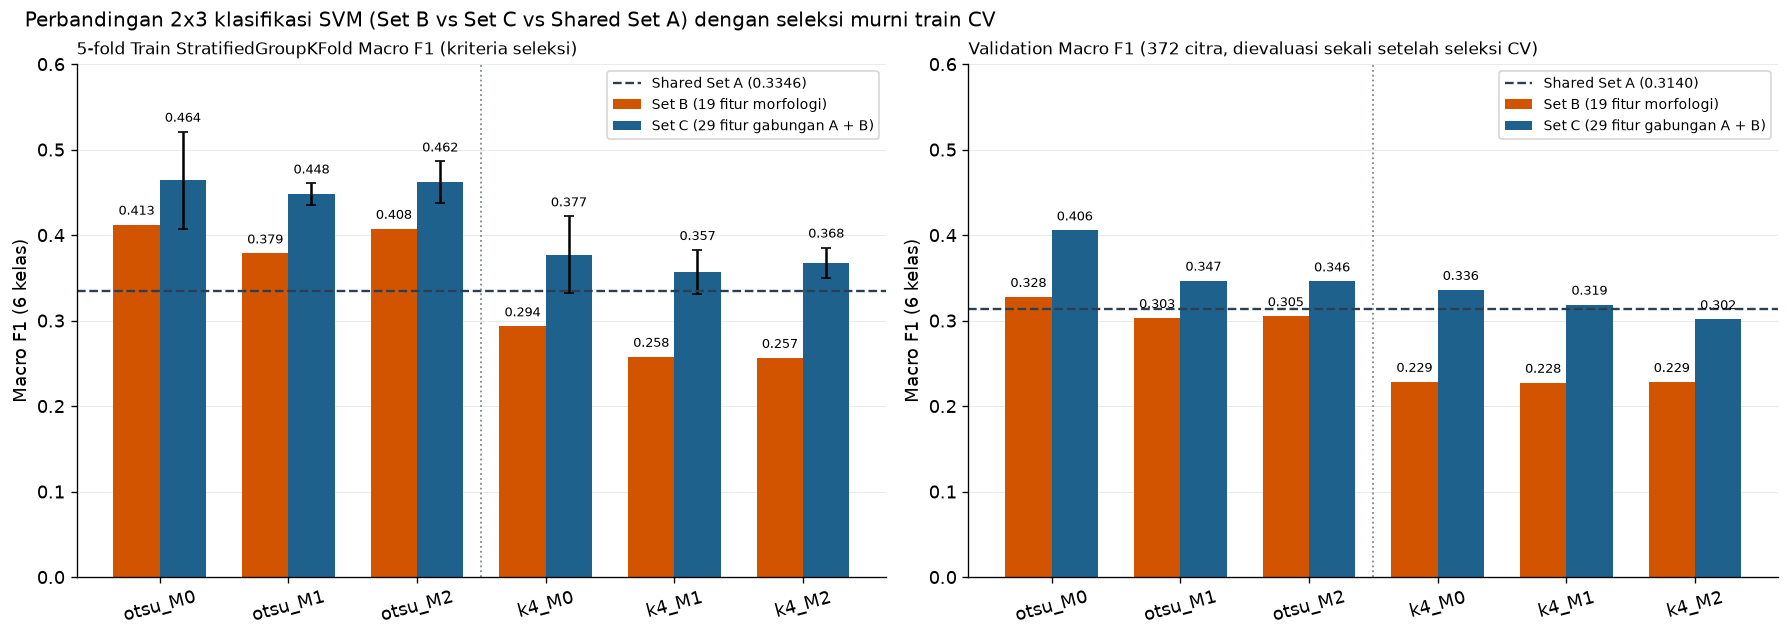

In [3]:
cv_sel_only = summary_df.loc[summary_df["model_variant"].eq("cv_selected")].copy()
def_only = summary_df.loc[summary_df["model_variant"].eq("default_rbf")].set_index(["method", "feature_set"])
cv_sel_only["default_rbf_val_macro_f1"] = [
    float(def_only.loc[(row["method"], row["feature_set"]), "val_macro_f1"])
    for _, row in cv_sel_only.iterrows()
]

display_cols = [
    "track",
    "method",
    "feature_set",
    "n_features",
    "kernel",
    "class_weight",
    "C",
    "gamma",
    "cv_macro_f1",
    "cv_fold_macro_f1_mean",
    "cv_fold_macro_f1_std",
    "val_macro_f1",
    "val_balanced_accuracy",
    "val_accuracy",
    "default_rbf_val_macro_f1",
]
display(
    cv_sel_only[display_cols].style.format(
        {
            "C": "{:.1f}",
            "cv_macro_f1": "{:.4f}",
            "cv_fold_macro_f1_mean": "{:.4f}",
            "cv_fold_macro_f1_std": "{:.4f}",
            "val_macro_f1": "{:.4f}",
            "val_balanced_accuracy": "{:.4f}",
            "val_accuracy": "{:.4f}",
            "default_rbf_val_macro_f1": "{:.4f}",
        }
    )
)

# 2x3 grouped comparison plot: Set B vs Set C on both CV and Validation + Shared A reference
shared_a = cv_sel_only.loc[cv_sel_only["method"].eq(SHARED_APPEARANCE_METHOD)].iloc[0]
b_sub = cv_sel_only.loc[cv_sel_only["track"].eq("factorial_2x3") & cv_sel_only["feature_set"].eq("B")].set_index("method").loc[list(FEATURE_METHODS)]
c_sub = cv_sel_only.loc[cv_sel_only["track"].eq("factorial_2x3") & cv_sel_only["feature_set"].eq("C")].set_index("method").loc[list(FEATURE_METHODS)]

fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.2), layout="constrained")
x = np.arange(len(FEATURE_METHODS))
w = 0.36

for ax, metric_col, err_col, ref_val, title in [
    (axes[0], "cv_macro_f1", "cv_fold_macro_f1_std", float(shared_a["cv_macro_f1"]), "5-fold Train StratifiedGroupKFold Macro F1 (kriteria seleksi)"),
    (axes[1], "val_macro_f1", None, float(shared_a["val_macro_f1"]), "Validation Macro F1 (372 citra, dievaluasi sekali setelah seleksi CV)"),
]:
    b_vals = b_sub[metric_col].to_numpy(dtype=float)
    c_vals = c_sub[metric_col].to_numpy(dtype=float)
    bars_b = ax.bar(x - w / 2, b_vals, width=w, color="#D35400", label="Set B (19 fitur morfologi)")
    bars_c = ax.bar(
        x + w / 2,
        c_vals,
        width=w,
        yerr=c_sub[err_col].to_numpy(dtype=float) if err_col else None,
        capsize=3.0 if err_col else 0.0,
        color="#1F618D",
        label="Set C (29 fitur gabungan A + B)",
    )
    ax.axhline(ref_val, color="#2C3E50", linestyle="--", linewidth=1.4, label=f"Shared Set A ({ref_val:.4f})")
    for bar, val in zip(bars_b, b_vals):
        ax.text(bar.get_x() + bar.get_width() / 2.0, val + 0.008, f"{val:.3f}", ha="center", va="bottom", fontsize=7.6)
    err_arr = c_sub[err_col].to_numpy(dtype=float) if err_col else np.zeros_like(c_vals)
    for bar, val, err in zip(bars_c, c_vals, err_arr):
        ax.text(bar.get_x() + bar.get_width() / 2.0, val + err + 0.008, f"{val:.3f}", ha="center", va="bottom", fontsize=7.6)
    ax.axvline(2.5, color="#7F8C8D", linestyle=":", linewidth=1.1)
    ax.set_xticks(x, list(FEATURE_METHODS), rotation=15)
    ax.set_ylim(0.0, 0.60)
    ax.set_ylabel("Macro F1 (6 kelas)")
    ax.set_title(title, loc="left", fontsize=10.2)
    ax.legend(frameon=True, fontsize=8.3, loc="upper right")
    ax.grid(axis="y", color="#EAEAEA", linewidth=0.6)

fig.suptitle(
    "Perbandingan 2x3 klasifikasi SVM (Set B vs Set C vs Shared Set A) dengan seleksi murni train CV",
    fontsize=12.2,
    x=0.01,
    ha="left",
)
finish_figure(
    fig,
    export_path=(ROOT / "reports/figures/07_2x3_classification_overview.png") if EXPORT_FIGURES else None,
)


### Temuan 2 — hasil menyeluruh desain 2×3: `otsu` vs `k4` dan perubahan tahap `M0 → M1 → M2`

- **Shared Set A (10 fitur *appearance*, independen segmentasi):** dengan seleksi CV (`rbf, C=10.0, gamma='scale', none`), Set A memperoleh `cv_macro_f1 = 0,3346` (`fold_mean = 0,3311 ± 0,0371`) dan `val_macro_f1 = 0,3140` (`val_accuracy = 49,73%`).
- **Keluarga `otsu` (`otsu_M0`, `otsu_M1`, `otsu_M2`) jauh mengungguli seluruh konfigurasi `k4` (`k4_M0`, `k4_M1`, `k4_M2`) pada Set B maupun Set C:**
  - **Set B (morfologi murni):** ketiga metode Otsu mencatat `cv_macro_f1` **`0,3789–0,4126`** (`val_macro_f1 = 0,3033–0,3280`), sedangkan ketiga metode `k4` hanya mencapai **`0,2567–0,2937`** (`val_macro_f1 = 0,2276–0,2287`). Menariknya, morfologi murni `otsu_M0_B` (`0,3280`) masih melampaui *baseline* warna/tekstur `Shared A` (`0,3140`), sedangkan morfologi `k4` justru tertinggal di bawah Set A!
  - **Set C (gabungan A + B):** setiap konfigurasi memperoleh peningkatan nyata atas Set B (+`0,049` hingga +`0,111` poin CV Macro F1), dan kembali seluruh metode Otsu (`cv_macro_f1 = 0,4481–0,4642`; `val_macro_f1 = 0,3462–0,4058`) mengungguli `k4` (`cv_macro_f1 = 0,3571–0,3774`; `val_macro_f1 = 0,3021–0,3362`).
- **Konfigurasi terbaik di bawah seleksi CV yang adil adalah `svm_otsu_M0_C` (`linear, C=3.0, class_weight='none'`):** memperoleh **`cv_macro_f1 = 0,4642`** sekaligus **`val_macro_f1 = 0,4058`**, **`val_balanced_accuracy = 0,4016`**, dan **`val_accuracy = 56,72%`** (naik `+0,0919` Macro F1 dan `+6,99%` akurasi atas `Shared A`).
- **Efek tahap morfologi `M0` $\rightarrow$ `M1` $\rightarrow$ `M2` tidak monoton naik:** pada *kedua* keluarga, penyaringan komponen `< 16 piksel` (`M1`) menurunkan CV Macro F1 baik di Otsu (`M0 -> M1`: `0,4126 -> 0,3789` Set B; `0,4642 -> 0,4481` Set C) maupun di K-means `k=4` (`M0 -> M1`: `0,2937 -> 0,2580` Set B; `0,3774 -> 0,3571` Set C). Hal ini menunjukkan bahwa partikel/noktah gelap kecil (`< 16 px`, misalnya inti sel padat) membawa sinyal histologis yang hilang ketika disaring `M1`.


## 3. Korelasi langsung kualitas segmentasi (`Dice` / `IoU`) terhadap performa klasifikasi hilir (`Macro-F1`, `Balanced Accuracy`, `Accuracy`)

Bagian ini menjawab pertanyaan inti protokol 2×3: apakah kualitas segmentasi yang lebih tinggi terhadap anotasi referensi (`val_mean_category_dice` / `val_mean_category_iou`) berkorespondensi dengan fitur morfologi yang lebih informatif dan klasifikasi SVM yang lebih baik?


,method,feature_set,seg_val_mean_category_dice,seg_val_mean_category_iou,train_val_mean_fg_fraction,train_val_mean_component_count,train_val_zero_perim_pct,kernel,class_weight,C,gamma,cv_macro_f1,val_macro_f1,val_balanced_accuracy,val_accuracy,delta_val_macro_f1_vs_shared_A,delta_val_macro_f1_C_minus_B
0,otsu_M0,B,0.7232,0.5788,0.5433,201.1,32.13%,rbf,balanced,10.0,0.01,0.4126,0.3280,0.3781,0.4355,+0.0141,+0.0778
1,otsu_M0,C,0.7232,0.5788,0.5433,201.1,32.13%,linear,none,3.0,scale,0.4642,0.4058,0.4016,0.5672,+0.0919,+0.0778
2,otsu_M1,B,0.7248,0.5811,0.5304,62.5,0.00%,rbf,balanced,10.0,0.01,0.3789,0.3033,0.3576,0.3817,-0.0106,+0.0437
3,otsu_M1,C,0.7248,0.5811,0.5304,62.5,0.00%,rbf,balanced,3.0,0.01,0.4481,0.3470,0.4171,0.4516,+0.0331,+0.0437
4,otsu_M2,B,0.7288,0.5886,0.5269,69.5,0.00%,rbf,balanced,10.0,0.01,0.4077,0.3055,0.3393,0.4113,-0.0085,+0.0407
5,otsu_M2,C,0.7288,0.5886,0.5269,69.5,0.00%,rbf,balanced,3.0,0.01,0.4622,0.3462,0.4240,0.4462,+0.0322,+0.0407
6,k4_M0,B,0.7761,0.6427,0.8527,26.4,49.50%,rbf,balanced,3.0,scale,0.2937,0.2287,0.2871,0.2876,-0.0852,+0.1075
7,k4_M0,C,0.7761,0.6427,0.8527,26.4,49.50%,rbf,balanced,10.0,0.01,0.3774,0.3362,0.4135,0.4328,+0.0222,+0.1075
8,k4_M1,B,0.7760,0.6426,0.8513,5.2,0.00%,rbf,balanced,10.0,scale,0.2580,0.2276,0.2820,0.3065,-0.0863,+0.0913
9,k4_M1,C,0.7760,0.6426,0.8513,5.2,0.00%,linear,none,10.0,scale,0.3571,0.3189,0.3198,0.5296,+0.0050,+0.0913


,feature_set,seg_metric,cls_metric,pearson_r,pearson_p,spearman_rho,spearman_p
0,B,val_mean_category_dice,cv_macro_f1,-0.9667,0.0016,-0.7143,0.1108
1,B,val_mean_category_dice,val_macro_f1,-0.9886,0.0002,-0.7714,0.0724
2,B,val_mean_category_dice,val_balanced_accuracy,-0.9274,0.0077,-0.7714,0.0724
3,B,val_mean_category_dice,val_accuracy,-0.5583,0.2495,-0.6000,0.2080
4,C,val_mean_category_dice,cv_macro_f1,-0.9826,0.0005,-0.7714,0.0724
5,C,val_mean_category_dice,val_macro_f1,-0.7562,0.0819,-0.7714,0.0724
6,C,val_mean_category_dice,val_balanced_accuracy,-0.6882,0.1307,-0.2571,0.6228
7,C,val_mean_category_dice,val_accuracy,-0.1144,0.8292,-0.4857,0.3287


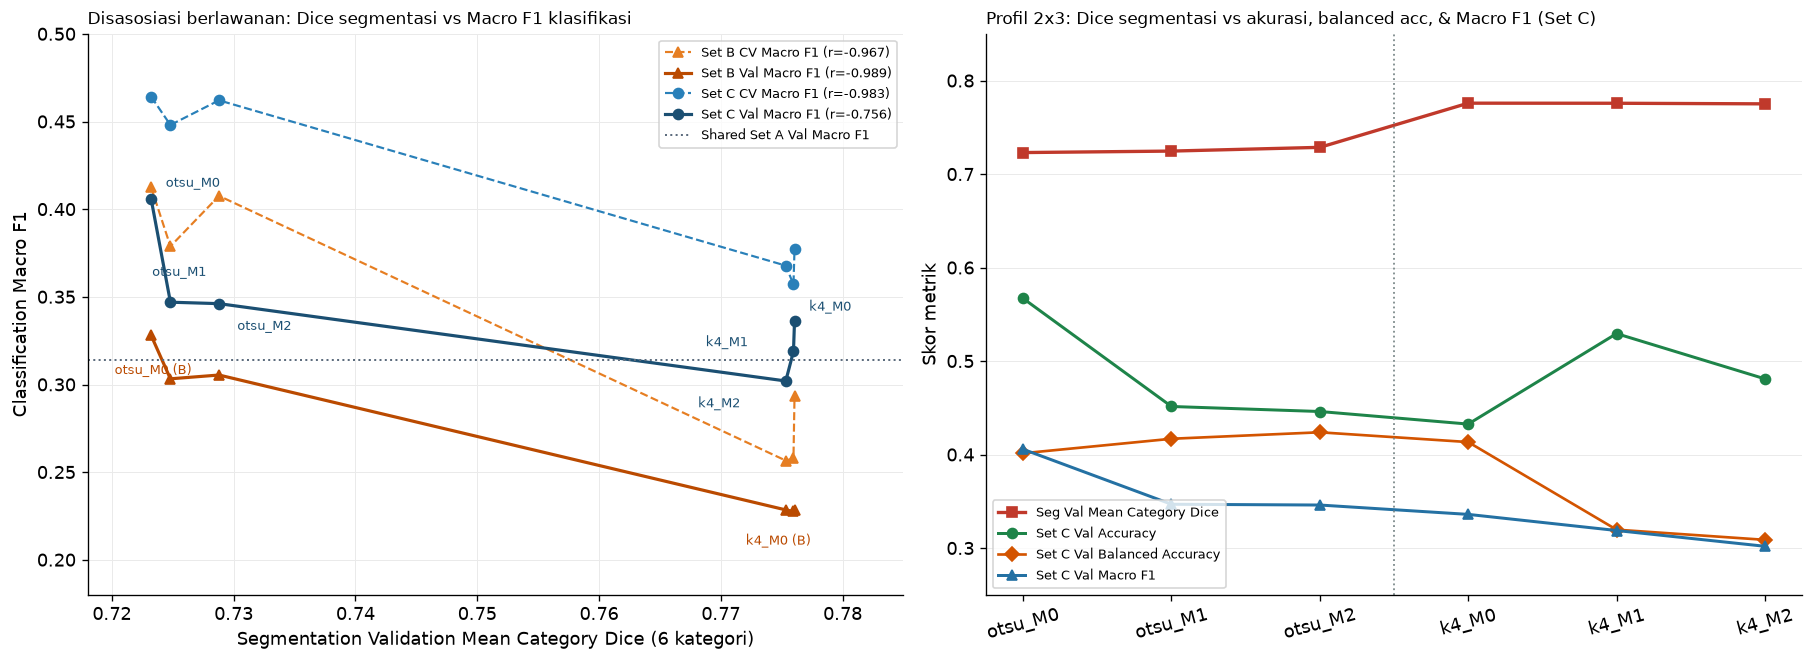

In [4]:
seg_cls_show = seg_cls_df[
    [
        "method",
        "feature_set",
        "seg_val_mean_category_dice",
        "seg_val_mean_category_iou",
        "train_val_mean_fg_fraction",
        "train_val_mean_component_count",
        "train_val_zero_perim_pct",
        "kernel",
        "class_weight",
        "C",
        "gamma",
        "cv_macro_f1",
        "val_macro_f1",
        "val_balanced_accuracy",
        "val_accuracy",
        "delta_val_macro_f1_vs_shared_A",
        "delta_val_macro_f1_C_minus_B",
    ]
].copy()

display(
    seg_cls_show.style.format(
        {
            "seg_val_mean_category_dice": "{:.4f}",
            "seg_val_mean_category_iou": "{:.4f}",
            "train_val_mean_fg_fraction": "{:.4f}",
            "train_val_mean_component_count": "{:.1f}",
            "train_val_zero_perim_pct": "{:.2f}%",
            "C": "{:.1f}",
            "cv_macro_f1": "{:.4f}",
            "val_macro_f1": "{:.4f}",
            "val_balanced_accuracy": "{:.4f}",
            "val_accuracy": "{:.4f}",
            "delta_val_macro_f1_vs_shared_A": "{:+.4f}",
            "delta_val_macro_f1_C_minus_B": "{:+.4f}",
        }
    )
)

corr_payload = cls_manifest["segmentation_vs_classification_correlations"]
corr_rows = []
for fset in ("B", "C"):
    for pair_key, stats_dict in corr_payload[fset].items():
        if pair_key.startswith("seg_val_mean_category_dice"):
            cls_metric = pair_key.replace("seg_val_mean_category_dice_vs_", "")
            corr_rows.append(
                {
                    "feature_set": fset,
                    "seg_metric": "val_mean_category_dice",
                    "cls_metric": cls_metric,
                    "pearson_r": stats_dict["pearson_r"],
                    "pearson_p": stats_dict["pearson_pvalue"],
                    "spearman_rho": stats_dict["spearman_rho"],
                    "spearman_p": stats_dict["spearman_pvalue"],
                }
            )
display(pd.DataFrame(corr_rows).style.format({"pearson_r": "{:+.4f}", "pearson_p": "{:.4f}", "spearman_rho": "{:+.4f}", "spearman_p": "{:.4f}"}))

fig_sc, axes_sc = plt.subplots(1, 2, figsize=(15.0, 5.4), layout="constrained")

# Panel A: Segmentation Dice vs Classification Macro F1 (CV and Val) for Set B & Set C
for fset, marker, color_cv, color_val in [
    ("B", "^", "#E67E22", "#BA4A00"),
    ("C", "o", "#2980B9", "#1B4F72"),
]:
    sub = seg_cls_df.loc[seg_cls_df["feature_set"].eq(fset)].sort_values("seg_val_mean_category_dice")
    xd = sub["seg_val_mean_category_dice"].to_numpy(dtype=float)
    y_cv = sub["cv_macro_f1"].to_numpy(dtype=float)
    y_va = sub["val_macro_f1"].to_numpy(dtype=float)

    r_cv = corr_payload[fset]["seg_val_mean_category_dice_vs_cv_macro_f1"]["pearson_r"]
    r_va = corr_payload[fset]["seg_val_mean_category_dice_vs_val_macro_f1"]["pearson_r"]

    axes_sc[0].plot(xd, y_cv, marker=marker, linestyle="--", linewidth=1.3, color=color_cv, label=f"Set {fset} CV Macro F1 (r={r_cv:+.3f})")
    axes_sc[0].plot(xd, y_va, marker=marker, linestyle="-", linewidth=1.9, color=color_val, label=f"Set {fset} Val Macro F1 (r={r_va:+.3f})")

    if fset == "C":
        offsets_c = {
            "otsu_M0": (0.0012, 0.007),
            "otsu_M1": (-0.0015, 0.015),
            "otsu_M2": (0.0015, -0.015),
            "k4_M0": (0.0012, 0.006),
            "k4_M1": (-0.0072, 0.003),
            "k4_M2": (-0.0072, -0.015),
        }
        for _, row in sub.iterrows():
            dx, dy = offsets_c.get(str(row["method"]), (0.0005, 0.008))
            axes_sc[0].annotate(
                str(row["method"]),
                (float(row["seg_val_mean_category_dice"]) + dx, float(row["val_macro_f1"]) + dy),
                fontsize=8.0,
                color=color_val,
            )
    else:
        offsets_b = {
            "otsu_M0": (-0.0030, -0.022),
            "k4_M0": (-0.0040, -0.020),
        }
        for _, row in sub.iterrows():
            m_str = str(row["method"])
            if m_str in offsets_b:
                dx, dy = offsets_b[m_str]
                axes_sc[0].annotate(
                    f"{m_str} (B)",
                    (float(row["seg_val_mean_category_dice"]) + dx, float(row["val_macro_f1"]) + dy),
                    fontsize=7.6,
                    color=color_val,
                )

axes_sc[0].axhline(float(shared_a["val_macro_f1"]), color="#5D6D7E", linestyle=":", linewidth=1.2, label="Shared Set A Val Macro F1")
axes_sc[0].set_xlabel("Segmentation Validation Mean Category Dice (6 kategori)")
axes_sc[0].set_ylabel("Classification Macro F1")
axes_sc[0].set_title("Disasosiasi berlawanan: Dice segmentasi vs Macro F1 klasifikasi", loc="left", fontsize=10.3)
axes_sc[0].set_ylim(0.18, 0.50)
axes_sc[0].set_xlim(0.718, 0.785)
axes_sc[0].legend(frameon=True, fontsize=7.8, loc="upper right")
axes_sc[0].grid(color="#EAEAEA", linewidth=0.6)

# Panel B: Trajectories across the 2x3 ordering for Dice vs Set C Accuracy / BalAcc / Macro-F1
pos = np.arange(len(FEATURE_METHODS))
c_ordered = seg_cls_df.loc[seg_cls_df["feature_set"].eq("C")].set_index("method").loc[list(FEATURE_METHODS)]
axes_sc[1].plot(pos, c_ordered["seg_val_mean_category_dice"], marker="s", linewidth=2.0, color="#C0392B", label="Seg Val Mean Category Dice")
axes_sc[1].plot(pos, c_ordered["val_accuracy"], marker="o", linewidth=1.8, color="#1E8449", label="Set C Val Accuracy")
axes_sc[1].plot(pos, c_ordered["val_balanced_accuracy"], marker="D", linewidth=1.6, color="#D35400", label="Set C Val Balanced Accuracy")
axes_sc[1].plot(pos, c_ordered["val_macro_f1"], marker="^", linewidth=1.8, color="#2471A3", label="Set C Val Macro F1")
axes_sc[1].axvline(2.5, color="#7F8C8D", linestyle=":", linewidth=1.1)
axes_sc[1].set_xticks(pos, list(FEATURE_METHODS), rotation=15)
axes_sc[1].set_ylim(0.25, 0.85)
axes_sc[1].set_ylabel("Skor metrik")
axes_sc[1].set_title("Profil 2x3: Dice segmentasi vs akurasi, balanced acc, & Macro F1 (Set C)", loc="left", fontsize=10.3)
axes_sc[1].legend(frameon=True, fontsize=8.1, loc="lower left")
axes_sc[1].grid(axis="y", color="#EAEAEA", linewidth=0.6)

finish_figure(
    fig_sc,
    export_path=(ROOT / "reports/figures/07_2x3_seg_dice_vs_classification.png") if EXPORT_FIGURES else None,
)


### Temuan 3 — korelasi negatif kuat antara *Dice* segmentasi dan performa klasifikasi hilir

- **Temuan statistik lintas enam konfigurasi 2×3:** skor segmentasi *validation mean category Dice* berkorelasi **negatif sangat kuat** dengan kemampuan klasifikasi SVM hilir:
  - Pada **Set B (morfologi saja)**: Pearson **`r = −0,9667`** (*p* = 0,0016) terhadap `cv_macro_f1`, **`r = −0,9886`** (*p* = 0,0002) terhadap `val_macro_f1`, dan **`r = −0,9274`** (*p* = 0,0077) terhadap `val_balanced_accuracy` (Spearman $\rho = -0,71$ s.d. $-0,77$).
  - Pada **Set C (gabungan 29 fitur)**: Pearson **`r = −0,9826`** (*p* = 0,0005) terhadap `cv_macro_f1` dan **`r = −0,7562`** (*p* = 0,0819) terhadap `val_macro_f1` (Spearman $\rho = -0,7714$).
- **Penjelasan mekanis:** *ground-truth mask* EBHI-SEG memberi anotasi area jaringan kelenjar/tumor yang luas (mencakup 35 citra *full-foreground*), sehingga `k4` yang menandai **85%–87% seluruh citra** mendapat Dice tinggi (`0,775–0,776`) namun **menghapus bentuk kelenjar dan kompleks epitel**. Sebaliknya, Otsu (`Dice 0,723–0,729`, cakupan `53%–54%`) mengekstrak pulau epitel serta struktur gelap yang bentuk dan fragmentasinya jauh lebih informatif membedakan `Adenocarcinoma`, `Low-grade IN`, dan `Polyp`.


## 4. Analisis *hyperparameter search*, efek `class_weight`, dan kontras protokol `v1` vs `v2`

Mengapa di dalam keluarga Otsu pada evaluasi `val` terjadi lompatan antara `otsu_M0` (`0,4058`) dan `otsu_M1`/`otsu_M2` (`0,3470` / `0,3462`), padahal di `cv_macro_f1` `otsu_M0` (`0,4642`) dan `otsu_M2` (`0,4622`) hampir imbang? Sel ini memeriksa tabel *best `none` vs best `balanced`* untuk tiap konfigurasi pada grid 32 spesifikasi agar mekanismenya terlihat transparan.


,method,class_weight,kernel,C,gamma,cv_macro_f1,cv_balanced_accuracy,val_macro_f1,val_balanced_accuracy,val_accuracy,is_selected_best
14,otsu_M0,balanced,rbf,3.0,0.01,0.4587,0.5217,0.3187,0.3667,0.4435,False
15,otsu_M0,none,linear,3.0,scale,0.4642,0.4428,0.4058,0.4016,0.5672,True
18,otsu_M1,balanced,rbf,3.0,0.01,0.4481,0.5076,0.3470,0.4171,0.4516,True
19,otsu_M1,none,rbf,10.0,scale,0.4221,0.4097,0.3676,0.3738,0.5591,False
22,otsu_M2,balanced,rbf,3.0,0.01,0.4622,0.5190,0.3462,0.4240,0.4462,True
23,otsu_M2,none,linear,1.0,scale,0.4541,0.4389,0.4262,0.4354,0.5968,False
2,k4_M0,balanced,rbf,10.0,0.01,0.3774,0.4168,0.3362,0.4135,0.4328,True
3,k4_M0,none,rbf,10.0,0.01,0.3661,0.3552,0.3625,0.3486,0.5430,False
6,k4_M1,balanced,rbf,10.0,0.01,0.3568,0.3827,0.2951,0.3489,0.3898,False
7,k4_M1,none,linear,10.0,scale,0.3571,0.3477,0.3189,0.3198,0.5296,True


,v1_spec,v1_val_macro_f1,v2_cv_spec,v2_cv_macro_f1,v2_val_macro_f1
otsu_M0,rbf none C=10 g=0.01,0.3976,linear none C=3 g=scale,0.4642,0.4058
otsu_M2,rbf none C=10 g=0.01,0.4587,rbf balanced C=3 g=0.01,0.4622,0.3462
k4_M0,rbf none C=10 g=0.01,0.3625,rbf balanced C=10 g=0.01,0.3774,0.3362
k4_M1,rbf none C=10 g=0.01,0.3311,linear none C=10 g=scale,0.3571,0.3189


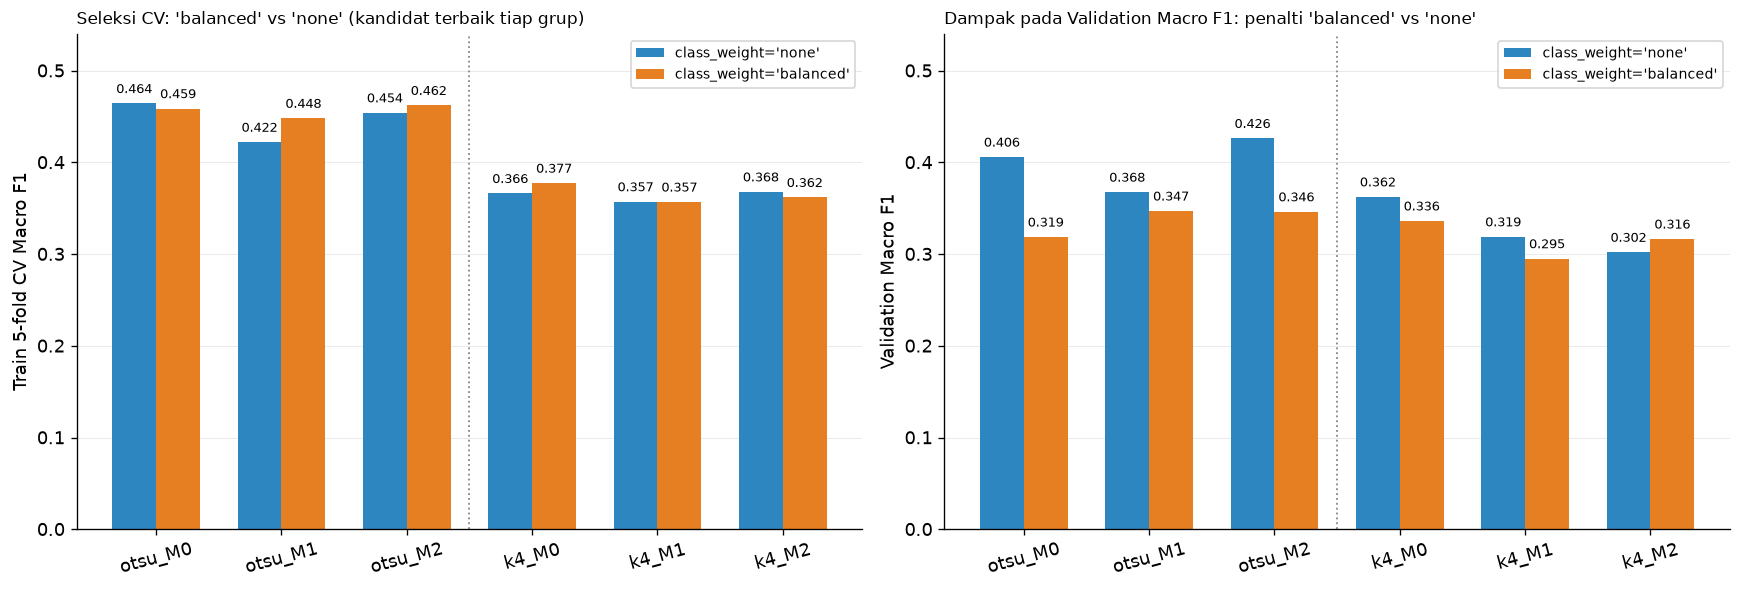

In [5]:
fact_grid = grid_df.loc[grid_df["track"].eq("factorial_2x3")].copy()
cw_best = (
    fact_grid.sort_values(
        ["cv_macro_f1", "cv_balanced_accuracy", "cv_accuracy"],
        ascending=False,
    )
    .groupby(["method", "feature_set", "class_weight"], observed=True)
    .first()
    .reset_index()
)
cw_c = cw_best.loc[cw_best["feature_set"].eq("C")].copy()
cw_c["method"] = pd.Categorical(cw_c["method"], categories=list(FEATURE_METHODS), ordered=True)
cw_c = cw_c.sort_values(["method", "class_weight"])

display(
    cw_c[
        [
            "method",
            "class_weight",
            "kernel",
            "C",
            "gamma",
            "cv_macro_f1",
            "cv_balanced_accuracy",
            "val_macro_f1",
            "val_balanced_accuracy",
            "val_accuracy",
            "is_selected_best",
        ]
    ].style.format(
        {
            "C": "{:.1f}",
            "cv_macro_f1": "{:.4f}",
            "cv_balanced_accuracy": "{:.4f}",
            "val_macro_f1": "{:.4f}",
            "val_balanced_accuracy": "{:.4f}",
            "val_accuracy": "{:.4f}",
        }
    )
)

# Compare preserved v1 protocol vs fair v2 CV-selected protocol on shared methods
legacy_comp = pd.read_csv(protected_files["legacy_cls_comp"])
legacy_c = legacy_comp.loc[
    legacy_comp["feature_set"].eq("C") & legacy_comp["spec_variant"].eq("primary_tuned_spec")
].set_index("method")
v2_c = seg_cls_df.loc[seg_cls_df["feature_set"].eq("C")].set_index("method")
proto_diff = pd.DataFrame(
    {
        "v1_spec": [
            f"{legacy_c.loc[m, 'kernel']} {legacy_c.loc[m, 'class_weight']} C={legacy_c.loc[m, 'C']:g} g={legacy_c.loc[m, 'gamma']}"
            for m in ("otsu_M0", "otsu_M2", "k4_M0", "k4_M1")
        ],
        "v1_val_macro_f1": [float(legacy_c.loc[m, "val_macro_f1"]) for m in ("otsu_M0", "otsu_M2", "k4_M0", "k4_M1")],
        "v2_cv_spec": [
            f"{v2_c.loc[m, 'kernel']} {v2_c.loc[m, 'class_weight']} C={v2_c.loc[m, 'C']:g} g={v2_c.loc[m, 'gamma']}"
            for m in ("otsu_M0", "otsu_M2", "k4_M0", "k4_M1")
        ],
        "v2_cv_macro_f1": [float(v2_c.loc[m, "cv_macro_f1"]) for m in ("otsu_M0", "otsu_M2", "k4_M0", "k4_M1")],
        "v2_val_macro_f1": [float(v2_c.loc[m, "val_macro_f1"]) for m in ("otsu_M0", "otsu_M2", "k4_M0", "k4_M1")],
    },
    index=["otsu_M0", "otsu_M2", "k4_M0", "k4_M1"],
)
display(proto_diff.style.format({"v1_val_macro_f1": "{:.4f}", "v2_cv_macro_f1": "{:.4f}", "v2_val_macro_f1": "{:.4f}"}))

fig_cw, axes_cw = plt.subplots(1, 2, figsize=(14.4, 4.8), layout="constrained")
none_c = cw_c.loc[cw_c["class_weight"].eq("none")].set_index("method").loc[list(FEATURE_METHODS)]
bal_c = cw_c.loc[cw_c["class_weight"].eq("balanced")].set_index("method").loc[list(FEATURE_METHODS)]
px = np.arange(len(FEATURE_METHODS))
bw = 0.35

for ax, col, ylab, title in [
    (axes_cw[0], "cv_macro_f1", "Train 5-fold CV Macro F1", "Seleksi CV: 'balanced' vs 'none' (kandidat terbaik tiap grup)"),
    (axes_cw[1], "val_macro_f1", "Validation Macro F1", "Dampak pada Validation Macro F1: penalti 'balanced' vs 'none'"),
]:
    v_none = none_c[col].to_numpy(dtype=float)
    v_bal = bal_c[col].to_numpy(dtype=float)
    b1 = ax.bar(px - bw / 2, v_none, width=bw, color="#2E86C1", label="class_weight='none'")
    b2 = ax.bar(px + bw / 2, v_bal, width=bw, color="#E67E22", label="class_weight='balanced'")
    for b, v in zip(b1, v_none):
        ax.text(b.get_x() + b.get_width() / 2.0, v + 0.008, f"{v:.3f}", ha="center", va="bottom", fontsize=7.6)
    for b, v in zip(b2, v_bal):
        ax.text(b.get_x() + b.get_width() / 2.0, v + 0.008, f"{v:.3f}", ha="center", va="bottom", fontsize=7.6)
    ax.axvline(2.5, color="#7F8C8D", linestyle=":", linewidth=1.1)
    ax.set_xticks(px, list(FEATURE_METHODS), rotation=15)
    ax.set_ylim(0.0, 0.54)
    ax.set_ylabel(ylab)
    ax.set_title(title, loc="left", fontsize=10.1)
    ax.legend(frameon=True, fontsize=8.3, loc="upper right")
    ax.grid(axis="y", color="#EAEAEA", linewidth=0.6)

finish_figure(
    fig_cw,
    export_path=(ROOT / "reports/figures/07_2x3_cw_tradeoff.png") if EXPORT_FIGURES else None,
)


### Temuan 4 — efek `class_weight='balanced'` di CV vs `val`, serta koreksi bias seleksi `v1`

- **Mengapa peringkat `otsu_M2` dan `otsu_M0` bergeser dari `v1` ke `v2`?**
  - Pada protokol `v1`, pemilihan hiperparameter memakai skor `val` (`k4_M0 C` dipilih sebagai `rbf, none, C=10, g=0.01`) lalu spesifikasi `none` tersebut diterapkan ke `otsu_M2`, sehingga `otsu_M2` tampak mencapai `val_macro_f1 = 0,4587`.
  - Ketika seleksi diperketat ke protokol `v2` yang **bebas kebocoran** (5-fold CV murni pada `train`), pembobotan `balanced` sedikit menaikkan `cv_macro_f1` pada `otsu_M2_C` (`0,4622` vs `0,4541` untuk `linear none C=1`). Namun di subset `val` yang kelas minoritasnya sangat kecil (`8` citra `Serrated adenoma`, `10` citra `Normal`), pembobotan `balanced` memperbanyak *false positive* kelas langka sehingga menurunkan presisi dan `val_macro_f1` (`0,3462`, kendati `val_balanced_accuracy = 0,4240` paling tinggi).
  - Sebaliknya, pada **`otsu_M0_C`**, *5-fold CV* sudah memilih **`linear, class_weight='none', C=3.0`** (`0,4642`), sehingga `otsu_M0_C` menjadi model paling seimbang sekaligus terbaik di **kedua** evaluasi: `cv_macro_f1 = 0,4642` dan `val_macro_f1 = 0,4058` (`val_accuracy = 56,72%`).


## 5. Metrik per kategori dan *confusion matrices* lintas 6 konfigurasi 2×3 (`Set C`), `Shared Set A`, dan `Set B` terbaik

Sel ini menyajikan:
1. Tabel **per-category F1 dan Recall** untuk `Shared Set A`, model Set B terbaik (`otsu_M0_B`), seluruh 6 model Set C pada grid 2×3, serta sensitivitas `k4_M0_A_seg` / `k4_M0_C_seg`.
2. Grid **2×3 *confusion matrix*** (Set C untuk keenam konfigurasi) beserta perbandingan berdampingan **`Shared Set A` vs `otsu_M0_B` vs `otsu_M0_C`**.


category,Adenocarcinoma,High-grade IN,Low-grade IN,Normal,Polyp,Serrated adenoma,Macro F1 (Val)
model_id,,,,,,,
svm_shared_A,0.4649,0.0667,0.4964,0.1739,0.6818,0.0000,0.3140
svm_otsu_M0_B,0.3465,0.2647,0.5429,0.1111,0.6404,0.0625,0.3280
svm_otsu_M0_C,0.5512,0.2759,0.5593,0.0952,0.7312,0.2222,0.4058
svm_otsu_M1_C,0.3469,0.2182,0.5650,0.1887,0.6744,0.0889,0.3470
svm_otsu_M2_C,0.4098,0.1639,0.5320,0.1887,0.6628,0.1200,0.3462
svm_k4_M0_C,0.3762,0.2041,0.4928,0.1905,0.6667,0.0870,0.3362
svm_k4_M1_C,0.5303,0.0870,0.5272,0.0952,0.6739,0.0000,0.3189
svm_k4_M2_C,0.4511,0.0000,0.4791,0.0870,0.6703,0.1250,0.3021
svm_k4_M0_A_seg,0.2011,0.0938,0.4242,0.1587,0.6303,0.0370,0.2575


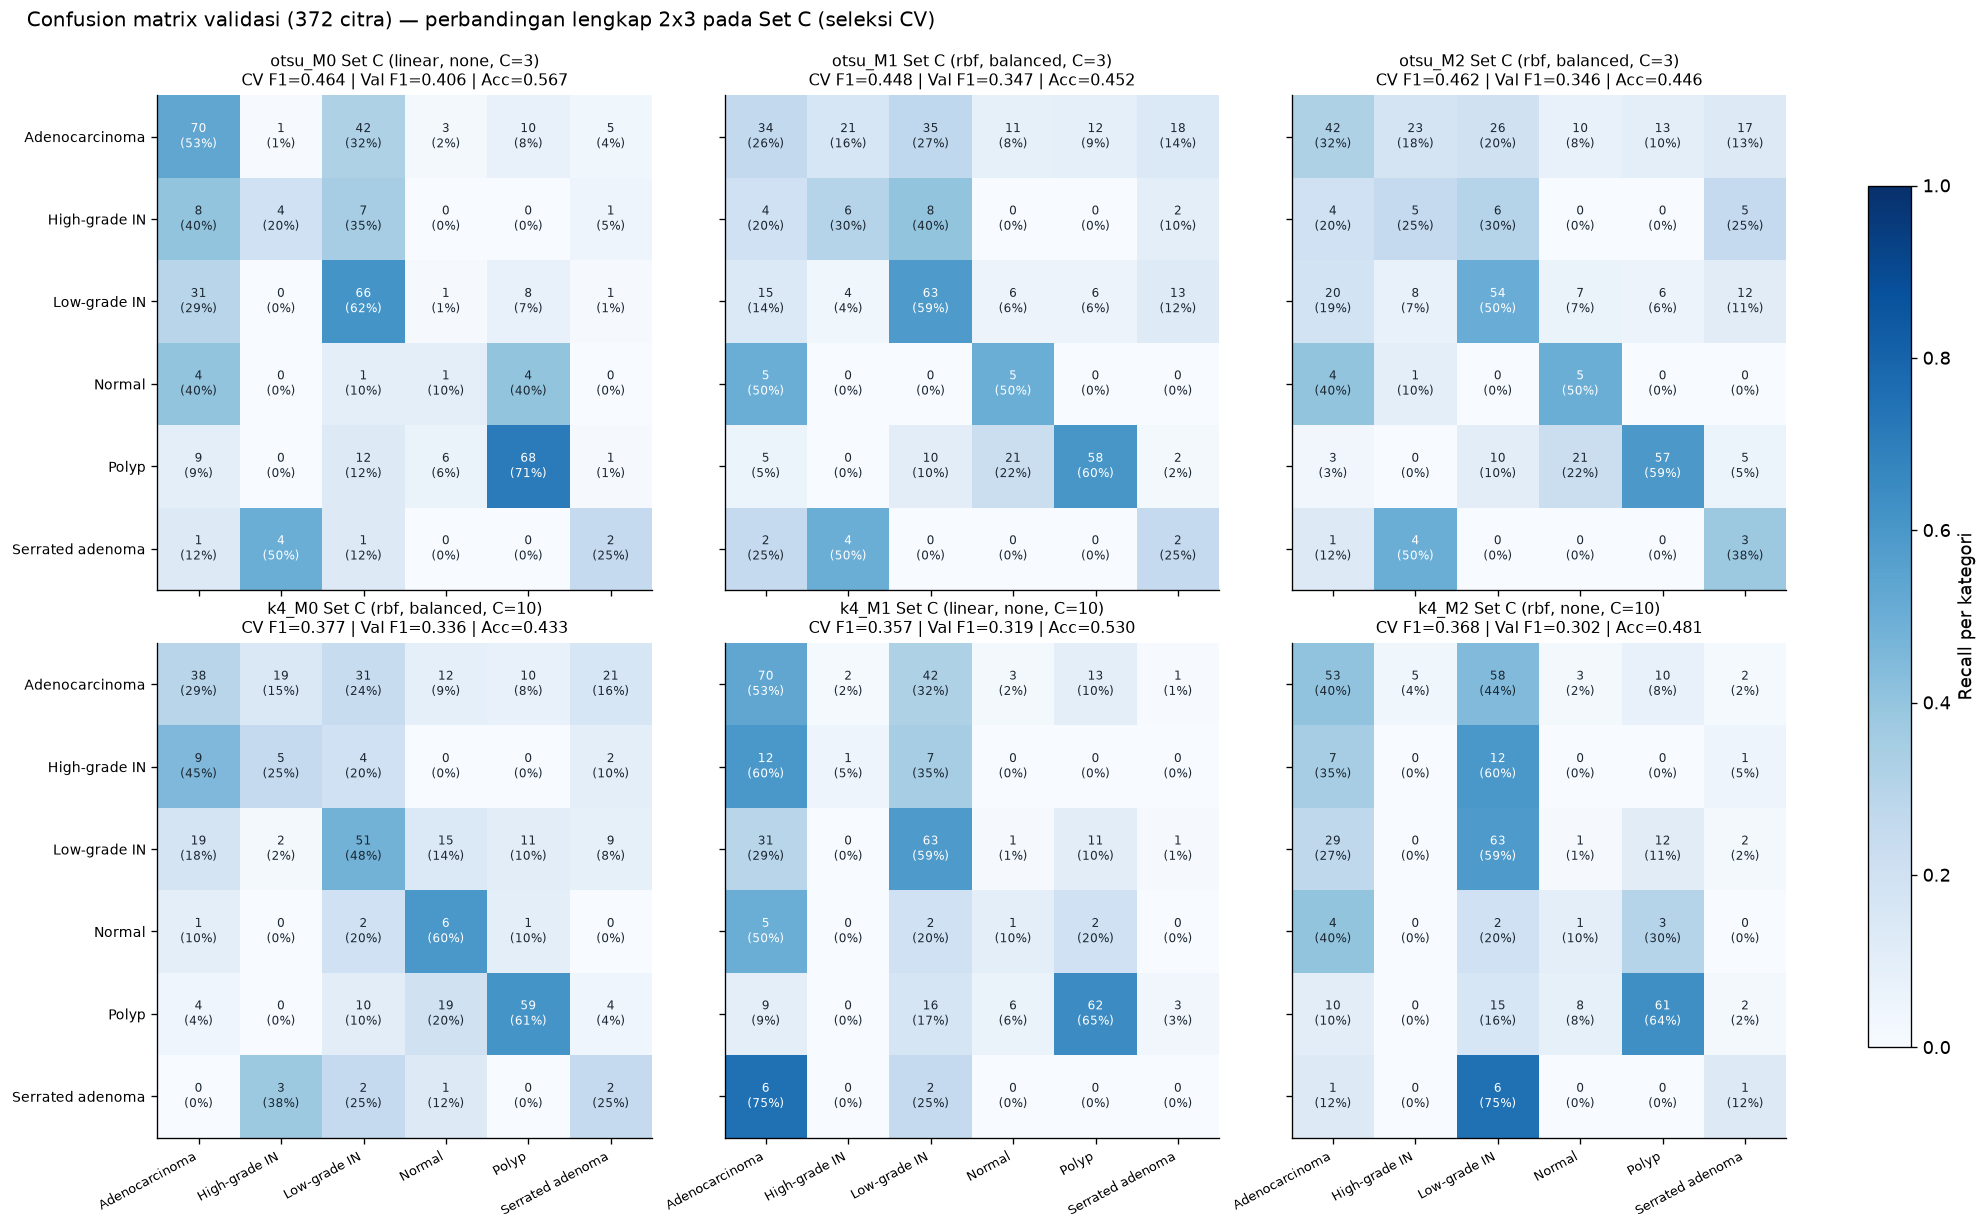

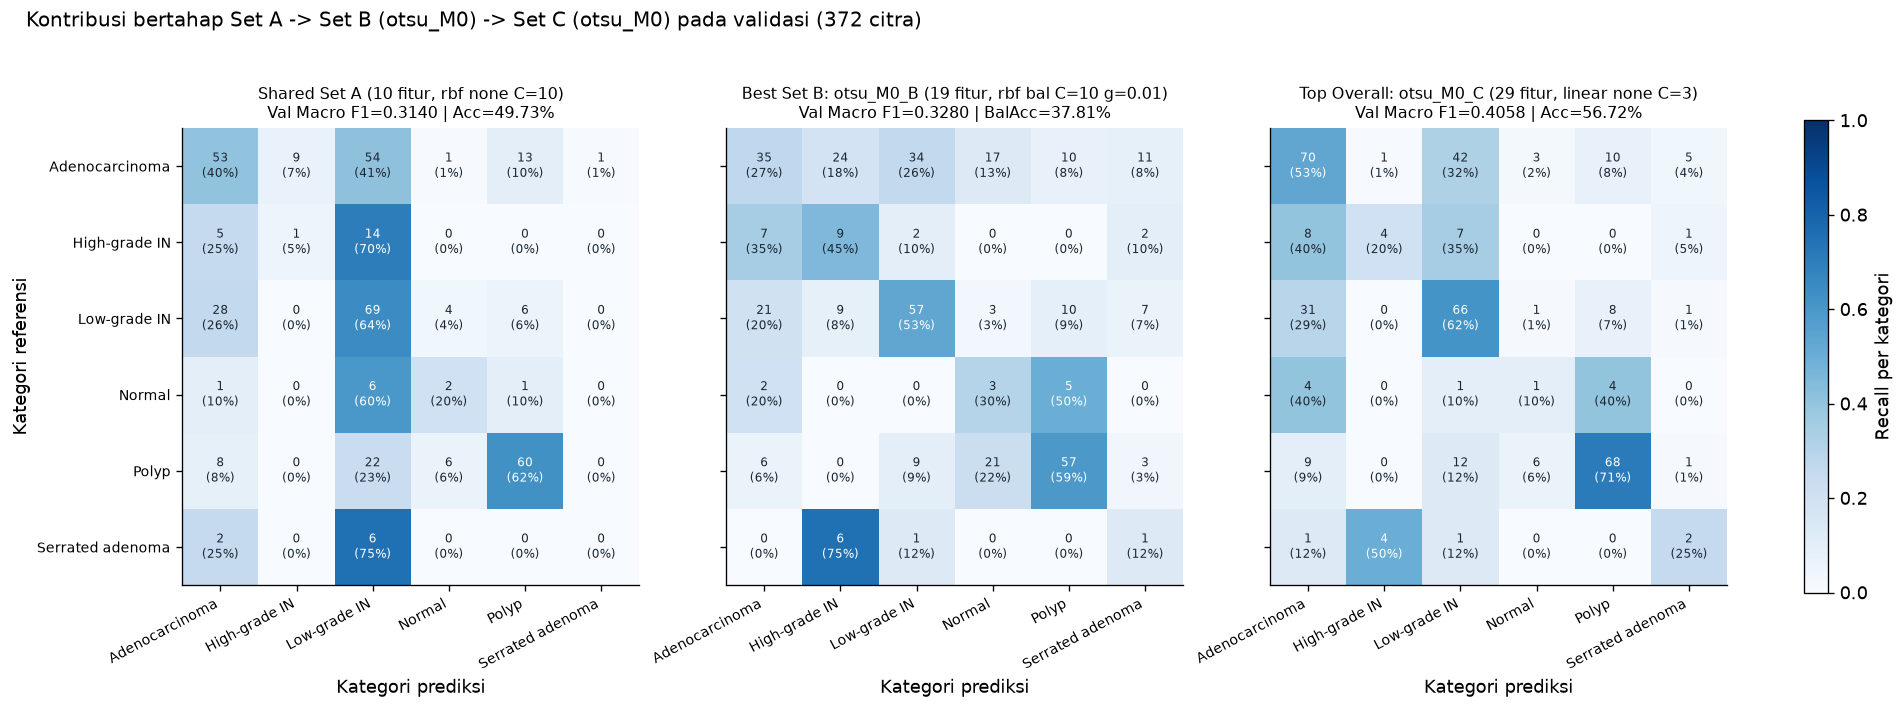

In [6]:
cat_cv_sel = per_cat_df.loc[per_cat_df["model_variant"].eq("cv_selected")].copy()
f1_pivot = cat_cv_sel.pivot(index="model_id", columns="category", values="f1")[list(EXPECTED_CATEGORIES)]
order_models = [
    "svm_shared_A",
    "svm_otsu_M0_B",
    "svm_otsu_M0_C",
    "svm_otsu_M1_C",
    "svm_otsu_M2_C",
    "svm_k4_M0_C",
    "svm_k4_M1_C",
    "svm_k4_M2_C",
    "svm_k4_M0_A_seg",
    "svm_k4_M0_C_seg",
]
f1_table = f1_pivot.reindex(order_models)
f1_table["Macro F1 (Val)"] = f1_table.mean(axis=1)
display(f1_table.style.format("{:.4f}"))

# 1. Complete 2x3 grid of confusion matrices for Set C
category_labels = list(EXPECTED_CATEGORIES)
fig_cm2x3, axes_2x3 = plt.subplots(2, 3, figsize=(16.5, 10.2), layout="constrained")
sel_preds = val_pred_df.loc[val_pred_df["model_variant"].eq("cv_selected")].copy()

for idx, (ax, method) in enumerate(zip(axes_2x3.ravel(), FEATURE_METHODS)):
    sub_p = sel_preds.loc[sel_preds["method"].eq(method) & sel_preds["feature_set"].eq("C")].sort_values("sample_id")
    cm_cnt = confusion_matrix_table(sub_p["category"], sub_p["predicted_category"], normalize=None)
    cm_nrm = confusion_matrix_table(sub_p["category"], sub_p["predicted_category"], normalize="true")
    m_info = v2_c.loc[method]
    im = ax.imshow(cm_nrm.to_numpy(), cmap="Blues", vmin=0.0, vmax=1.0)
    ax.set_xticks(np.arange(6), category_labels if idx >= 3 else [], rotation=28, ha="right", fontsize=8.0)
    ax.set_yticks(np.arange(6), category_labels if idx in (0, 3) else [], fontsize=8.2)
    ax.set_title(
        f"{method} Set C ({m_info['kernel']}, {m_info['class_weight']}, C={m_info['C']:g})\n"
        f"CV F1={m_info['cv_macro_f1']:.3f} | Val F1={m_info['val_macro_f1']:.3f} | Acc={m_info['val_accuracy']:.3f}",
        fontsize=9.3,
    )
    ax.grid(False)
    for r in range(6):
        for c in range(6):
            cnt = int(cm_cnt.iat[r, c])
            pct = 100.0 * float(cm_nrm.iat[r, c])
            ax.text(
                c,
                r,
                f"{cnt}\n({pct:.0f}%)",
                ha="center",
                va="center",
                fontsize=7.2,
                color="white" if pct >= 50.0 else "#1B2631",
            )

fig_cm2x3.colorbar(im, ax=axes_2x3, shrink=0.82, label="Recall per kategori")
fig_cm2x3.get_layout_engine().set(rect=(0.0, 0.0, 1.0, 0.95))
fig_cm2x3.suptitle(
    "Confusion matrix validasi (372 citra) — perbandingan lengkap 2x3 pada Set C (seleksi CV)",
    fontsize=12.0,
    x=0.01,
    y=0.985,
    ha="left",
)
finish_figure(
    fig_cm2x3,
    export_path=(ROOT / "reports/figures/07_2x3_confusion_matrices_set_C.png") if EXPORT_FIGURES else None,
)

# 2. Side-by-side comparison: Shared Set A vs Best Set B (otsu_M0_B) vs Best Set C (otsu_M0_C)
fig_abc, axes_abc = plt.subplots(1, 3, figsize=(15.8, 5.8), layout="constrained")
for ax, m_id, title in zip(
    axes_abc,
    ["svm_shared_A", "svm_otsu_M0_B", "svm_otsu_M0_C"],
    [
        "Shared Set A (10 fitur, rbf none C=10)\nVal Macro F1=0.3140 | Acc=49.73%",
        "Best Set B: otsu_M0_B (19 fitur, rbf bal C=10 g=0.01)\nVal Macro F1=0.3280 | BalAcc=37.81%",
        "Top Overall: otsu_M0_C (29 fitur, linear none C=3)\nVal Macro F1=0.4058 | Acc=56.72%",
    ],
):
    sub_p = sel_preds.loc[sel_preds["model_id"].eq(m_id)].sort_values("sample_id")
    cm_cnt = confusion_matrix_table(sub_p["category"], sub_p["predicted_category"], normalize=None)
    cm_nrm = confusion_matrix_table(sub_p["category"], sub_p["predicted_category"], normalize="true")
    im2 = ax.imshow(cm_nrm.to_numpy(), cmap="Blues", vmin=0.0, vmax=1.0)
    ax.set_xticks(np.arange(6), category_labels, rotation=28, ha="right", fontsize=8.2)
    ax.set_yticks(np.arange(6), category_labels if m_id == "svm_shared_A" else [], fontsize=8.4)
    if m_id == "svm_shared_A":
        ax.set_ylabel("Kategori referensi")
    ax.set_xlabel("Kategori prediksi")
    ax.set_title(title, fontsize=9.4)
    ax.grid(False)
    for r in range(6):
        for c in range(6):
            cnt = int(cm_cnt.iat[r, c])
            pct = 100.0 * float(cm_nrm.iat[r, c])
            ax.text(
                c,
                r,
                f"{cnt}\n({pct:.0f}%)",
                ha="center",
                va="center",
                fontsize=7.3,
                color="white" if pct >= 50.0 else "#1B2631",
            )

fig_abc.colorbar(im2, ax=axes_abc, shrink=0.82, label="Recall per kategori")
fig_abc.get_layout_engine().set(rect=(0.0, 0.0, 1.0, 0.91))
fig_abc.suptitle(
    "Kontribusi bertahap Set A -> Set B (otsu_M0) -> Set C (otsu_M0) pada validasi (372 citra)",
    fontsize=11.8,
    x=0.01,
    y=0.985,
    ha="left",
)
finish_figure(
    fig_abc,
    export_path=(ROOT / "reports/figures/07_2x3_confusion_matrices_shared_A_best_B_best_C.png") if EXPORT_FIGURES else None,
)


### Temuan 5 — pola pemisahan per kategori dan sensitivitas `A_seg` / `C_seg`

- **Keunggulan konsisten `svm_otsu_M0_C` lintas kategori:** dibanding `Shared Set A`, penggabungan fitur morfologi mentah Otsu menaikkan F1 pada **`Adenocarcinoma`** (`0,4649 -> 0,5512`), **`High-grade IN`** (`0,0667 -> 0,2759`), **`Low-grade IN`** (`0,4964 -> 0,5593`), **`Polyp`** (`0,6818 -> 0,7312`), dan memulihkan **`Serrated adenoma`** dari **`0,0000` menjadi `0,2222`**.
- **Sensitivitas sekunder `A_seg` dan `C_seg` pada `k4_M0`:** pembatasan perhitungan CIE Lab/GLCM ke area *foreground* `k4_M0` menaikkan `cv_macro_f1` dibanding `Shared Set A` (`0,3750` untuk `A_seg` dan `0,3777` untuk `C_seg` vs `0,3346`), namun gagal berujung perbaikan pada evaluasi `val` (`A_seg`: `0,2575`, `C_seg`: `0,2942` vs `k4_M0_C`: `0,3362` maupun `otsu_M0_C`: `0,4058`), menandakan bahwa informasi warna/tekstur stroma latar ikut membantu deskripsi warna global dan pembatasan oleh *mask* `k4_M0` yang terlalu luas belum efektif.


## 6. Reproduksi & verifikasi paritas ke-15 artefak model JSON portabel (`models/cv_2x3/`)

Sel ini memastikan ke-15 model `cv_selected` yang diekspor (`svm_shared_A`, `6 × Set B`, `6 × Set C`, `svm_k4_M0_A_seg`, `svm_k4_M0_C_seg`) dapat direproduksi secara deterministik dari tabel `train`, cocok dengan `sklearn.svm.SVC` hingga `<= 1e-10`, dan cocok persis dengan `svm_2x3_selected_summary.csv` serta `svm_2x3_val_predictions.csv`.


In [7]:
train_seg, val_seg, _ = load_classification_feature_frame(ROOT, method=PRIMARY_METHOD, segmented=True)
method_dev_frames = {m: load_classification_feature_frame(ROOT, method=m, segmented=False)[:2] for m in FEATURE_METHODS}

parity_rows = []
for art_rel in cls_manifest["exported_model_files"]:
    art_path = ROOT / art_rel
    artifact = load_svm_artifact(art_path)
    method = str(artifact["segmentation_method"])
    set_name = str(artifact["feature_set"])
    cols = feature_columns_for_set(set_name)

    if method == SHARED_APPEARANCE_METHOD:
        tr_f, va_f = train_app, val_app
    elif set_name in ("A_seg", "C_seg"):
        tr_f, va_f = train_seg, val_seg
    else:
        tr_f, va_f = method_dev_frames[method]

    X_tr_raw = tr_f[list(cols)].to_numpy(dtype=np.float64)
    y_tr = tr_f["category"].to_numpy(dtype=object)
    X_va_raw = va_f[list(cols)].to_numpy(dtype=np.float64)
    y_va = va_f["category"].to_numpy(dtype=object)

    sc_re = fit_standard_scaler(X_tr_raw, cols)
    np.testing.assert_allclose(sc_re["mean"], artifact["scaler"]["mean"], rtol=0.0, atol=1e-12)
    np.testing.assert_allclose(sc_re["scale"], artifact["scaler"]["scale"], rtol=0.0, atol=1e-12)

    clf = fit_svm_model(
        apply_standard_scaler(X_tr_raw, sc_re),
        y_tr,
        kernel=str(artifact["kernel"]),
        C=float(artifact["C"]),
        gamma=artifact["gamma_param"],
        class_weight=str(artifact["class_weight"]),
    )
    parity = verify_svm_artifact_parity(X_va_raw, clf, artifact, atol=DECISION_PARITY_ATOL)
    pred_labels, _, _ = predict_from_svm_artifact(X_va_raw, artifact)
    re_metrics = classification_metrics(y_va, pred_labels)
    for k, expected in artifact["validation_metrics"].items():
        assert abs(re_metrics[k] - float(expected)) < 1e-12

    parity_rows.append(
        {
            "model_id": artifact["model_id"],
            "method": method,
            "feature_set": set_name,
            "kernel": artifact["kernel"],
            "class_weight": artifact["class_weight"],
            "C": float(artifact["C"]),
            "gamma": artifact["gamma_param"],
            "max_abs_ovo_diff": float(parity["max_abs_decision_diff"]),
            "exact_label_match": bool(parity["exact_prediction_match"]),
            "val_macro_f1": float(re_metrics["macro_f1"]),
        }
    )

parity_df = pd.DataFrame(parity_rows)
display(
    parity_df.style.format(
        {
            "C": "{:.1f}",
            "max_abs_ovo_diff": "{:.3e}",
            "val_macro_f1": "{:.4f}",
        }
    )
)
assert parity_df["max_abs_ovo_diff"].max() <= DECISION_PARITY_ATOL
assert parity_df["exact_label_match"].all()
print(f"Paritas 15 artefak model JSON (models/cv_2x3/) lulus penuh (max_diff={parity_df['max_abs_ovo_diff'].max():.3e}).")


,model_id,method,feature_set,kernel,class_weight,C,gamma,max_abs_ovo_diff,exact_label_match,val_macro_f1
0,svm_k4_M0_A_seg,k4_M0,A_seg,linear,balanced,1.0,scale,1.147e-12,True,0.2575
1,svm_k4_M0_B,k4_M0,B,rbf,balanced,3.0,scale,7.436e-13,True,0.2287
2,svm_k4_M0_C,k4_M0,C,rbf,balanced,10.0,0.01,2.602e-12,True,0.3362
3,svm_k4_M0_C_seg,k4_M0,C_seg,linear,none,3.0,scale,4.064e-12,True,0.2942
4,svm_k4_M1_B,k4_M1,B,rbf,balanced,10.0,scale,2.331e-12,True,0.2276
5,svm_k4_M1_C,k4_M1,C,linear,none,10.0,scale,2.251e-11,True,0.3189
6,svm_k4_M2_B,k4_M2,B,rbf,none,10.0,scale,2.985e-12,True,0.2285
7,svm_k4_M2_C,k4_M2,C,rbf,none,10.0,scale,1.507e-12,True,0.3021
8,svm_otsu_M0_B,otsu_M0,B,rbf,balanced,10.0,0.01,4.888e-12,True,0.3280
9,svm_otsu_M0_C,otsu_M0,C,linear,none,3.0,scale,6.179e-12,True,0.4058


Paritas 15 artefak model JSON (models/cv_2x3/) lulus penuh (max_diff=2.251e-11).


## Kesimpulan & keterbatasan metodologis protokol 2×3

### Kesimpulan ilmiah utama
1. **Skor Dice segmentasi yang lebih tinggi tidak menghasilkan fitur morfologi yang lebih informatif maupun klasifikasi yang lebih akurat:** pada keenam konfigurasi 2×3, hubungan antara `seg_val_mean_category_dice` dan Macro-F1 hilir justru **berkorelasi negatif kuat** ($r = -0,9886$ pada Set B validasi, $r = -0,9826$ pada Set C *5-fold CV*). *Lab K-means k=4* mengoptimalkan tumpang-tindih wilayah kasar (`85%–87%` luas citra, Dice `0,775–0,776`) namun melebur batas epitel–stroma, sedangkan *Otsu* (`53%–54%` luas citra, Dice `0,723–0,729`) mempertahankan separasi pulau epitel/nukleus yang esensial untuk klasifikasi histologi.
2. **Tahap `M0` mengungguli `M1` dan `M2` di kedua keluarga pada seleksi CV:** penghapusan partikel `< 16 piksel` (`M1`) menghilangkan informasi densitas inti gelap kecil sehingga menurunkan CV Macro-F1 baik pada `otsu` maupun `k4`.
3. **Model teratas di bawah pencarian hiperparameter identik bebas-kebocoran adalah `otsu_M0` + Set C (`svm_otsu_M0_C`, `linear, C=3.0, none`):** mencapai `cv_macro_f1 = 0,4642` dan `val_macro_f1 = 0,4058` (`val_accuracy = 56,72%`), mengungguli *baseline appearance* bersama `Shared Set A` (`0,3140` Val Macro-F1) maupun `k4_M0_C` (`0,3362`).

### Keterbatasan dan disiplin subset `test`
- Ketimpangan kelas minoritas yang ekstrem pada `val` (`Serrated adenoma` `n=8`, `Normal` `n=10`) membuat model dengan `class_weight='balanced'` rentan mengalami penurunan presisi saat dievaluasi di luar lipatan latih meski skor CV-nya sedikit lebih tinggi.
- Seluruh artefak evaluasi akhir `test` sebelumnya (`v1`) tetap dibekukan terpisah dan **tidak diakses maupun dijalankan ulang** di dalam studi perluasan 2×3 ini.


In [8]:
input_hashes_after = {name: sha256_bytes(path) for name, path in protected_files.items()}
assert input_hashes_after == input_hashes_before, "Artefak yang dilindungi berubah saat notebook dieksekusi."
print(
    "Selesai: studi 2x3 (Shared A + 6x{B, C} + A_seg/C_seg) dengan seleksi CV train-only terverifikasi; "
    "0 citra test disentuh; seluruh artefak v1 & v2 tetap identik."
)


Selesai: studi 2x3 (Shared A + 6x{B, C} + A_seg/C_seg) dengan seleksi CV train-only terverifikasi; 0 citra test disentuh; seluruh artefak v1 & v2 tetap identik.
